# TP 3 — Normaliser et encoder : préparer les données pour un modèle — **CORRIGÉ ENSEIGNANT**
**Analyse de données — Master IA / Master RSD** · Chapitre 2 : sections 6 (Normalisation) et 7 (Encodage)

*Mettre les variables à la même échelle, transformer le texte en nombres, sans introduire de relations artificielles.*

**Objectifs du TP**
1. **Identifier la nature** de chaque variable (quantitative, nominale, ordinale, cible).
2. **Normaliser** les variables numériques : Z-score, Min-Max, transformation logarithmique → *choisir la méthode adaptée*.
3. **Encoder** les variables catégorielles : One-Hot, Ordinal, Label → *éviter les pièges classiques*.
4. **Assembler** une préparation reproductible (`ColumnTransformer`) et **mesurer son effet** sur un modèle k-NN.
5. **Documenter** chaque décision dans ce notebook.

| Volume | Organisation | Données | Livrable |
|---|---|---|---|
| 2 séances de 2 h (4 h au total) | Binômes · Notebook Jupyter | `clients_enrichi.csv` (fictif, fourni) | Notebook complété + conclusions |

⭐ **Continuité :** `clients_enrichi.csv` est le fichier **nettoyé du TP 2** (988 clients, sans valeur manquante), enrichi de trois variables catégorielles : `ville`, `niveau_etude`, `satisfaction`.

**Mode d'emploi** : complétez les cellules marquées `# TODO`, puis exécutez la cellule **✅ Auto-correction** qui suit. Répondez aux questions dans les cellules **✍️**.

## Partie 0 — Génération du jeu de données (enseignant)
1. On rejoue le nettoyage du TP 2 sur `clients_brut.csv` (doublons, modalités, âges, code 999 999, imputation k-NN) → 988 clients.
2. On ajoute, avec une graine fixe :
   - `ville` (**nominale**) : Oran, Alger, Constantine, Béchar, Annaba — tirée au hasard ;
   - `niveau_etude` (**ordinale**) : Licence < Master < Doctorat — **liée au revenu** (plus le revenu est élevé, plus le niveau tend à l'être) ;
   - `satisfaction` (**ordinale**) : faible < moyenne < elevee — tirée au hasard.

In [1]:
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer

# 1. Nettoyage du TP 2
df = pd.read_csv("../TP2/FR/clients_brut.csv", sep=";").drop_duplicates()
df["segment"] = df["segment"].replace({"a": "A", "b": "B"})
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df = df[df["age"].between(0, 120)].copy()
df.loc[df["revenu"] == 999999, "revenu"] = np.nan
num = ["age", "revenu", "nb_enfants", "anciennete", "nb_achats"]
df["revenu"] = KNNImputer(n_neighbors=5).fit_transform(df[num])[:, 1].round(-2)
df = df.sort_values("id").reset_index(drop=True)

# 2. Trois variables catégorielles
rng = np.random.default_rng(2028)              # graine fixe -> fichier identique à chaque exécution
n = len(df)
df["ville"] = rng.choice(["Oran", "Alger", "Constantine", "Béchar", "Annaba"], n, p=[.3, .3, .2, .1, .1])
log_rev = np.log(df["revenu"])
score = (log_rev - log_rev.mean()) / log_rev.std() + rng.normal(0, 1, n)     # revenu + bruit
df["niveau_etude"] = pd.cut(score, [-np.inf, -0.5, 0.9, np.inf], labels=["Licence", "Master", "Doctorat"]).astype(str)
df["satisfaction"] = rng.choice(["faible", "moyenne", "elevee"], n, p=[.25, .45, .3])

df = df[["id", "age", "revenu", "nb_enfants", "anciennete", "nb_achats",
         "ville", "niveau_etude", "satisfaction", "email", "segment"]]
df.astype({"age": int, "revenu": int}).to_csv("../TP3/FR/clients_enrichi.csv", sep=";", index=False, encoding="utf-8")
print("clients_enrichi.csv écrit :", df.shape)

clients_enrichi.csv écrit : (988, 11)


---
## Mise en place

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

---
## Étape 1 — Identifier la nature de chaque variable
*La méthode dépend de la nature **et** du rôle de la variable* (section 7, bonne pratique ①).

### 1.0 Charger le fichier

In [3]:
df = pd.read_csv("../TP3/FR/clients_enrichi.csv", sep=";")

print(df.shape)
df.head()

(988, 11)


,id,age,revenu,nb_enfants,anciennete,nb_achats,ville,niveau_etude,satisfaction,email,segment
0,1,18,49200,2,3,7,Alger,Doctorat,elevee,client0001@exemple.dz,C
1,2,87,54900,3,10,12,Alger,Doctorat,elevee,client0002@exemple.dz,A
2,3,55,40200,1,13,17,Constantine,Master,faible,client0003@exemple.dz,A
3,4,67,31600,1,11,3,Annaba,Master,moyenne,client0004@exemple.dz,C
4,5,40,60300,0,13,17,Béchar,Doctorat,elevee,client0005@exemple.dz,A


✅ **Auto-correction**

In [4]:
assert df.shape == (988, 11), f"Attendu (988, 11), obtenu {df.shape} -> séparateur ?"
assert df.isna().sum().sum() == 0, "le fichier est déjà nettoyé : aucune valeur manquante"
print("✅ 1.0 correct")

✅ 1.0 correct


### 1.1 Classer les variables
On veut **prédire le `segment`** du client (A, B ou C) à partir des autres variables.
Pour chaque colonne, indiquez sa nature parmi : `"identifiant"`, `"quantitative"`, `"nominale"`, `"ordinale"`, `"cible"`.

💡 Regardez les modalités avec `df["colonne"].unique()` en cas de doute.

In [5]:
for col in ["ville", "niveau_etude", "satisfaction", "segment"]:
    print(f"{col:13s}", sorted(df[col].unique()))

ville         ['Alger', 'Annaba', 'Béchar', 'Constantine', 'Oran']
niveau_etude  ['Doctorat', 'Licence', 'Master']
satisfaction  ['elevee', 'faible', 'moyenne']
segment       ['A', 'B', 'C']


In [6]:
nature = {
    "id":           "identifiant",
    "age":          "quantitative",
    "revenu":       "quantitative",
    "nb_enfants":   "quantitative",
    "anciennete":   "quantitative",
    "nb_achats":    "quantitative",
    "ville":        "nominale",      # aucun ordre entre Oran, Alger, Béchar...
    "niveau_etude": "ordinale",      # Licence < Master < Doctorat
    "satisfaction": "ordinale",      # faible < moyenne < elevee
    "email":        "identifiant",   # unique par client, aucune information utile
    "segment":      "cible",         # ce qu'on veut prédire
}

✅ **Auto-correction**

In [7]:
assert nature["ville"] == "nominale", "y a-t-il un ordre naturel entre les villes ?"
assert nature["niveau_etude"] == nature["satisfaction"] == "ordinale"
assert nature["segment"] == "cible"
assert nature["id"] == nature["email"] == "identifiant"
assert all(nature[c] == "quantitative" for c in ["age", "revenu", "nb_enfants", "anciennete", "nb_achats"])
print("✅ 1.1 correct")

✅ 1.1 correct


In [8]:
# Ces listes servent dans tout le TP
num_cols = [c for c, t in nature.items() if t == "quantitative"]
nom_cols = [c for c, t in nature.items() if t == "nominale"]
ord_cols = [c for c, t in nature.items() if t == "ordinale"]
print("numériques :", num_cols)
print("nominales  :", nom_cols)
print("ordinales  :", ord_cols)

numériques : ['age', 'revenu', 'nb_enfants', 'anciennete', 'nb_achats']
nominales  : ['ville']
ordinales  : ['niveau_etude', 'satisfaction']


💡 *Débat utile* : `nb_enfants` est un entier à peu de valeurs (0 à 6). On le traite comme **quantitatif** (il a un sens numérique : 4 enfants = 2 × 2 enfants), pas comme une catégorie.

---
## Étape 2 — Normaliser les variables numériques (section 6)

### 2.1 Le problème : des échelles différentes
Affichez les statistiques descriptives des variables numériques. Comparez l'**étendue** de `age` et de `revenu`.

In [9]:
display(df[num_cols].describe().round(1))

etendue_age = df["age"].max() - df["age"].min()
etendue_revenu = df["revenu"].max() - df["revenu"].min()
print(etendue_age, etendue_revenu, round(etendue_revenu / etendue_age))

,age,revenu,nb_enfants,anciennete,nb_achats
count,988.0,988.0,988.0,988.0,988.0
mean,41.9,44663.7,1.4,10.4,8.8
std,11.8,22579.6,1.2,6.1,4.2
min,18.0,9600.0,0.0,0.0,0.0
25%,33.8,28875.0,1.0,5.0,6.0
50%,42.0,39800.0,1.0,11.0,8.0
75%,50.0,55800.0,2.0,16.0,12.0
max,87.0,185000.0,6.0,20.0,25.0


69 175400 2542


✅ **Auto-correction**

In [10]:
assert etendue_age == 69
assert etendue_revenu / etendue_age > 2000, "le revenu varie plus de 2000 fois plus que l'âge"
print("✅ 2.1 correct")

✅ 2.1 correct


**Réponse attendue :** une différence de 10 000 DA de revenu pèse autant que 10 000 ans d'âge ! La distance est **écrasée par le revenu** ; l'âge, l'ancienneté ou le nombre d'achats ne comptent presque plus. Le modèle « ne voit » plus ces variables, même si elles sont informatives (on le mesurera à l'étape 4).

### 2.2 Méthode 1 — Standardisation (Z-score)
$$z = \frac{x - \mu}{\sigma}$$
1. Calculez `revenu_z` **à la main** avec la formule (utilisez `std(ddof=0)`, l'écart-type de la population, comme scikit-learn).
2. Calculez-le avec `StandardScaler` et vérifiez que vous obtenez la même chose.

In [11]:
revenu_z = (df["revenu"] - df["revenu"].mean()) / df["revenu"].std(ddof=0)

scaler = StandardScaler()
revenu_z_sk = scaler.fit_transform(df[["revenu"]]).ravel()

print(round(revenu_z.mean(), 6), round(revenu_z.std(ddof=0), 6))

0.0 1.0


✅ **Auto-correction**

In [12]:
assert np.allclose(revenu_z, revenu_z_sk), "la formule et StandardScaler doivent donner le même résultat"
assert abs(revenu_z.mean()) < 1e-9 and abs(revenu_z.std(ddof=0) - 1) < 1e-9, "moyenne 0, écart-type 1"
assert np.isclose(scaler.mean_[0], df["revenu"].mean()), "le scaler mémorise μ"
print("✅ 2.2 correct")

✅ 2.2 correct


💡 *À faire remarquer* : avec `std()` (ddof=1, par défaut dans pandas) l'écart-type obtenu vaut 0,9995 et non 1 → petite différence avec scikit-learn, qui utilise ddof=0.

### 2.3 Méthode 2 — Normalisation Min-Max
$$x' = \frac{x - x_{min}}{x_{max} - x_{min}} \in [0, 1]$$
Même exercice : à la main, puis avec `MinMaxScaler`.

In [13]:
revenu_mm = (df["revenu"] - df["revenu"].min()) / (df["revenu"].max() - df["revenu"].min())
revenu_mm_sk = MinMaxScaler().fit_transform(df[["revenu"]]).ravel()

✅ **Auto-correction**

In [14]:
assert np.allclose(revenu_mm, revenu_mm_sk)
assert revenu_mm.min() == 0 and revenu_mm.max() == 1
print("✅ 2.3 correct")

✅ 2.3 correct


### 2.4 Transformation logarithmique : corriger l'asymétrie
Le revenu est **asymétrique à droite** (vu au TP 2). Z-score et Min-Max **ne changent pas la forme** de la distribution ; le logarithme, si.

Calculez `revenu_log = np.log1p(revenu)` ($\log(1+x)$, défini même pour $x = 0$), puis comparez l'**asymétrie** (`skew()`) avant / après.

In [15]:
revenu_log = np.log1p(df["revenu"])

skew = pd.Series({
    "brut":    df["revenu"].skew(),
    "Z-score": revenu_z.skew(),
    "Min-Max": revenu_mm.skew(),
    "log":     revenu_log.skew(),
}).round(2)
skew

brut       1.42
Z-score    1.42
Min-Max    1.42
log       -0.08
dtype: float64

✅ **Auto-correction**

In [16]:
assert skew["brut"] == skew["Z-score"] == skew["Min-Max"], "Z-score et Min-Max conservent la forme"
assert abs(skew["log"]) < 0.3 < skew["brut"], "le log rend la distribution presque symétrique"
print("✅ 2.4 correct")

✅ 2.4 correct


Cellule fournie : les quatre versions du revenu côte à côte (comme sur la diapositive « Comparer : Z-score vs Min-Max »).

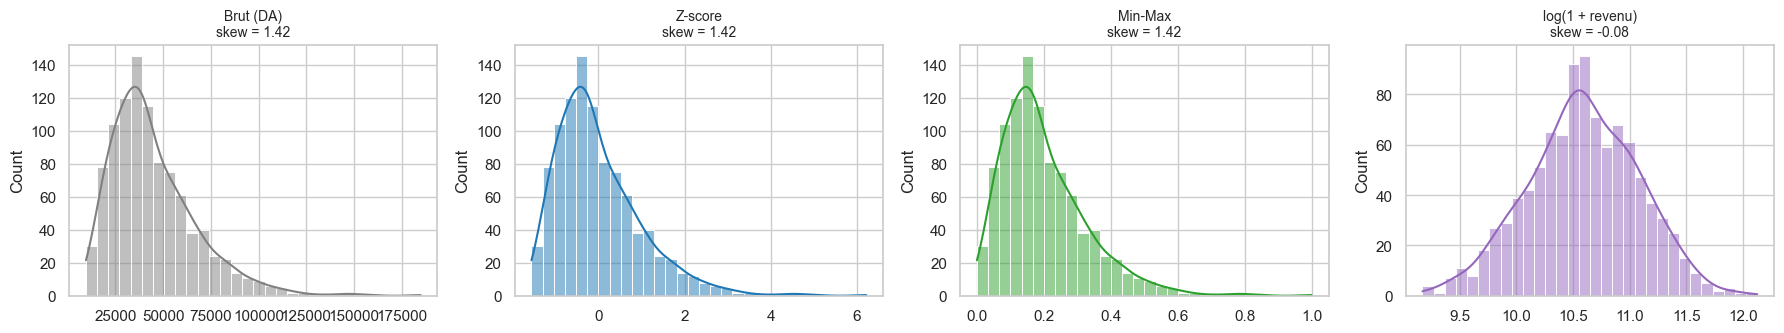

In [17]:
versions = {"Brut (DA)": df["revenu"], "Z-score": revenu_z, "Min-Max": revenu_mm, "log(1 + revenu)": revenu_log}
couleurs = ["gray", "tab:blue", "tab:green", "tab:purple"]

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, (titre, serie), c in zip(axes, versions.items(), couleurs):
    sns.histplot(serie, bins=30, kde=True, color=c, ax=ax)
    ax.set_title(f"{titre}\nskew = {serie.skew():.2f}", fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### 2.5 Sensibilité aux valeurs extrêmes
Au TP 2, on a remplacé le revenu **999 999** (erreur de saisie) par une valeur imputée. Que se serait-il passé si on l'avait **oublié** ?

Sur une copie du revenu où l'on remet **une** valeur à 999 999, calculez la **médiane** des valeurs transformées par Min-Max et par Z-score, avec et sans l'outlier.

In [18]:
avec_outlier = df["revenu"].copy()
avec_outlier.iloc[0] = 999999

def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

def zscore(s):
    return (s - s.mean()) / s.std(ddof=0)

effet = pd.DataFrame({
    "sans outlier": {"médiane Min-Max": minmax(df["revenu"]).median(), "médiane Z-score": zscore(df["revenu"]).median()},
    "avec outlier": {"médiane Min-Max": minmax(avec_outlier).median(), "médiane Z-score": zscore(avec_outlier).median()},
}).round(3)
effet

,sans outlier,avec outlier
médiane Min-Max,0.172,0.030
médiane Z-score,-0.216,-0.154


✅ **Auto-correction**

In [19]:
assert effet.loc["médiane Min-Max", "avec outlier"] < 0.05 < effet.loc["médiane Min-Max", "sans outlier"]
print("✅ 2.5 correct")

✅ 2.5 correct


**Réponses attendues**
1. Avec l'outlier, $x_{max}$ = 999 999 : tous les autres clients sont **comprimés** entre 0 et ≈ 0,18, la moitié sous ≈ 0,03. Min-Max est **très sensible** aux valeurs extrêmes. Le Z-score bouge aussi (μ et σ augmentent), mais moins brutalement : c'est pourquoi le cours conseille le Z-score en présence d'outliers.
2. **Revenu** : asymétrique avec une longue queue → **log** pour corriger la forme, **puis Z-score** pour la mise à l'échelle. **Âge** : distribution à peu près symétrique, bornée, sans outlier → Z-score (ou Min-Max) directement. En cas de doute : Z-score.

### 2.6 Bonne pratique : apprendre μ et σ sur l'entraînement uniquement
*« Toujours calculer μ et σ sur l'ensemble d'entraînement uniquement. Appliquer la même transformation sur validation, test et nouvelles données. »*

1. Séparez `df` en entraînement (80 %) et test (20 %) avec `train_test_split(..., test_size=0.2, random_state=42, stratify=df["segment"])`.
2. Ajustez (`fit`) un `StandardScaler` sur `num_cols` du **train** seulement, puis transformez (`transform`) train **et** test.

In [20]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["segment"])

scaler = StandardScaler()
scaler.fit(df_train[num_cols])
X_train_num = scaler.transform(df_train[num_cols])
X_test_num = scaler.transform(df_test[num_cols])

print("moyenne train :", X_train_num.mean(axis=0).round(3))
print("moyenne test  :", X_test_num.mean(axis=0).round(3))

moyenne train : [-0. -0. -0.  0. -0.]
moyenne test  : [ 0.076 -0.061  0.041 -0.045  0.013]


✅ **Auto-correction**

In [21]:
assert len(df_train) == 790 and len(df_test) == 198
assert np.allclose(X_train_num.mean(axis=0), 0), "le train est centré"
assert not np.allclose(X_test_num.mean(axis=0), 0), "le test ne doit PAS être exactement centré"
assert np.allclose(scaler.mean_, df_train[num_cols].mean()), "μ appris sur le train seulement"
print("✅ 2.6 correct")

✅ 2.6 correct


**Réponse attendue :** le test est transformé avec le μ et le σ **du train** ; ses propres moyennes sont proches mais pas égales. C'est voulu : le test joue le rôle de **nouvelles données** qu'on ne connaît pas au moment de l'apprentissage. Refaire `fit` sur le test (ou faire `fit` sur tout le jeu avant de séparer) laisse fuiter de l'information du test vers le modèle (**fuite de données**, *data leakage*) et donne une évaluation trop optimiste. En production, un seul client arrive à la fois : on ne pourrait même pas calculer sa « moyenne ».

---
## Étape 3 — Encoder les variables catégorielles (section 7)
Rappel du guide de décision : **ordre naturel ?** non → **One-Hot** ; oui → est-ce la **cible** ? oui → **Label**, non → **Ordinal**.

### 3.1 One-Hot Encoding — `ville` (nominale)
1. Encodez `ville` avec `pd.get_dummies(..., prefix="ville", dtype=int)`.
2. Refaites-le avec `drop_first=True`. Combien de colonnes dans chaque cas ?

In [22]:
ville_oh = pd.get_dummies(df["ville"], prefix="ville", dtype=int)
ville_oh_df = pd.get_dummies(df["ville"], prefix="ville", dtype=int, drop_first=True)

print(ville_oh.shape, ville_oh_df.shape)
ville_oh.head()

(988, 5) (988, 4)


,ville_Alger,ville_Annaba,ville_Béchar,ville_Constantine,ville_Oran
0,1,0,0,0,0
1,1,0,0,0,0
2,0,0,0,1,0
3,0,1,0,0,0
4,0,0,1,0,0


✅ **Auto-correction**

In [23]:
assert ville_oh.shape == (988, 5), "5 villes -> 5 colonnes binaires"
assert (ville_oh.sum(axis=1) == 1).all(), "exactement un 1 par ligne"
assert ville_oh_df.shape == (988, 4)
print("✅ 3.1 correct")

✅ 3.1 correct


**Réponses attendues**
1. La **première** modalité par ordre alphabétique : **Alger**. Un client d'Alger a **des 0 partout** : c'est la catégorie de référence. Cette colonne était redondante (elle se déduit des 4 autres), ce qui gêne certains modèles comme la régression linéaire (colinéarité).
2. Le modèle comprendrait **Oran < Alger < Béchar** et « Béchar = 2 × Alger » : un ordre et des distances **qui n'existent pas** (piège ① et ② de la diapositive « Pièges classiques »).

### 3.2 Ordinal Encoding — `niveau_etude` (ordinale)
1. Essayez d'abord `OrdinalEncoder()` **sans préciser l'ordre** (cellule fournie) : quel code reçoit chaque niveau ?
2. Corrigez en donnant l'ordre explicitement : `categories=[["Licence", "Master", "Doctorat"]]`.

In [24]:
piege = OrdinalEncoder().fit(df[["niveau_etude"]])
print("Ordre appris par défaut :", list(piege.categories_[0]))

Ordre appris par défaut : ['Doctorat', 'Licence', 'Master']


In [25]:
enc_niveau = OrdinalEncoder(categories=[["Licence", "Master", "Doctorat"]])
niveau_code = enc_niveau.fit_transform(df[["niveau_etude"]]).ravel()

pd.crosstab(df["niveau_etude"], niveau_code)

col_0,0.0,1.0,2.0
niveau_etude,,,
Doctorat,0,0,257
Licence,357,0,0
Master,0,374,0


✅ **Auto-correction**

In [26]:
codes = pd.Series(niveau_code, index=df.index).groupby(df["niveau_etude"]).first()
assert codes["Licence"] < codes["Master"] < codes["Doctorat"], "l'ordre naturel doit être respecté"
assert df["revenu"].corr(pd.Series(niveau_code, index=df.index)) > 0.4, "niveau et revenu sont liés"
print("✅ 3.2 correct")

✅ 3.2 correct


**Réponse attendue :** par défaut, `OrdinalEncoder` trie les modalités **par ordre alphabétique** : Doctorat = 0, Licence = 1, Master = 2. Le Doctorat devient le niveau « le plus bas » ! Le lien positif entre niveau et revenu serait cassé (la corrélation devient incohérente). Bonne pratique : **définir explicitement le mapping**. (Même piège pour `satisfaction` : par ordre alphabétique, elevee < faible < moyenne.)

### 3.3 Label Encoding — `segment` (cible)
Encodez la cible avec `LabelEncoder` et affichez le **mapping appris** (`le.classes_`).

In [27]:
le = LabelEncoder()
y = le.fit_transform(df["segment"])

mapping = dict(zip(le.classes_, le.transform(le.classes_)))
mapping

{'A': np.int64(0), 'B': np.int64(1), 'C': np.int64(2)}

✅ **Auto-correction**

In [28]:
assert list(le.classes_) == ["A", "B", "C"] and set(y) == {0, 1, 2}
assert (le.inverse_transform(y) == df["segment"]).all(), "on doit pouvoir revenir aux étiquettes"
print("✅ 3.3 correct")

✅ 3.3 correct


💡 *À rappeler* : `LabelEncoder` attend un vecteur 1D (une seule colonne) et est réservé à la **cible y**. Pour une classification, les entiers 0, 1, 2 sont de simples **étiquettes** : le modèle ne les compare pas.

### 3.4 Piège : une catégorie inconnue au moment de la prédiction
Un nouveau client arrive de **Tlemcen**, une ville absente des données d'entraînement.
1. Cellule fournie : un `OneHotEncoder` par défaut **plante**.
2. Créez `enc_ville` avec `handle_unknown="ignore"` et `sparse_output=False`, entraînez-le sur `df_train[["ville"]]`, puis encodez le nouveau client.

In [29]:
nouveau = pd.DataFrame({"ville": ["Tlemcen"]})

try:
    OneHotEncoder().fit(df_train[["ville"]]).transform(nouveau)
except ValueError as e:
    print("❌ Erreur :", str(e)[:90], "...")

❌ Erreur : Found unknown categories ['Tlemcen'] in column 0 during transform ...


In [30]:
enc_ville = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(df_train[["ville"]])
code_nouveau = enc_ville.transform(nouveau)

print(enc_ville.get_feature_names_out(), code_nouveau)

['ville_Alger' 'ville_Annaba' 'ville_Béchar' 'ville_Constantine'
 'ville_Oran'] [[0. 0. 0. 0. 0.]]


✅ **Auto-correction**

In [31]:
assert code_nouveau.shape == (1, 5) and code_nouveau.sum() == 0, "ville inconnue -> que des 0"
print("✅ 3.4 correct")

✅ 3.4 correct


💡 Avec `handle_unknown="ignore"`, la ville inconnue est encodée par **des 0 partout** : le modèle ne plante pas et se rabat sur les autres variables. Autre solution du cours : prévoir une catégorie « Autre ». Si une nouvelle catégorie devient fréquente, il faut **réentraîner** l'encodeur.

---
## Étape 4 — Assembler la préparation et mesurer son effet
Dans un vrai projet, on regroupe toutes les transformations dans un **`ColumnTransformer`** : chaque groupe de colonnes reçoit son traitement, et le même objet est appliqué au train et au test (bonne pratique ⑤ : *même encodage en entraînement et en test*).

### 4.1 Le `ColumnTransformer`
Complétez `prep` : `StandardScaler` sur `num_cols`, `OneHotEncoder` (inconnues ignorées) sur `nom_cols`, `OrdinalEncoder` avec les **deux** ordres sur `ord_cols`. `id`, `email` et `segment` ne sont pas des variables explicatives.

In [32]:
from sklearn.compose import ColumnTransformer

ordres = [["Licence", "Master", "Doctorat"], ["faible", "moyenne", "elevee"]]

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("nom", OneHotEncoder(handle_unknown="ignore"), nom_cols),
    ("ord", OrdinalEncoder(categories=ordres), ord_cols),
])

X_train = prep.fit_transform(df_train)   # fit sur le train
X_test = prep.transform(df_test)         # transform seulement sur le test
y_train, y_test = le.transform(df_train["segment"]), le.transform(df_test["segment"])

print(X_train.shape, X_test.shape)
pd.DataFrame(X_train, columns=prep.get_feature_names_out()).head()

(790, 12) (198, 12)


,num__age,num__revenu,num__nb_enfants,num__anciennete,num__nb_achats,nom__ville_Alger,nom__ville_Annaba,nom__ville_Béchar,nom__ville_Constantine,nom__ville_Oran,ord__niveau_etude,ord__satisfaction
0,1.200672,0.163882,0.494547,1.548415,0.516976,0.0,1.0,0.0,0.0,0.0,2.0,2.0
1,-1.408188,-1.097400,1.358911,-1.550066,0.280627,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,-0.314150,-0.386019,-0.369816,0.569947,0.280627,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.566620,0.320997,-1.234180,1.548415,1.698722,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,1.453143,0.181339,-0.369816,-1.060832,0.044278,0.0,0.0,0.0,0.0,1.0,1.0,1.0


✅ **Auto-correction**

In [33]:
assert X_train.shape == (790, 12) and X_test.shape == (198, 12), "5 numériques + 5 villes + 2 ordinales = 12"
assert "email" not in " ".join(prep.get_feature_names_out()), "l'email n'est pas une variable explicative"
print("✅ 4.1 correct")

✅ 4.1 correct


### 4.2 La normalisation change-t-elle le modèle ?
On prédit le `segment` avec un **k-NN** (k = 15), un modèle basé sur les distances. Comparez la **précision** (*accuracy*) sur le test :
- **sans normalisation** des variables numériques (`"passthrough"` à la place du `StandardScaler`) ;
- avec **Z-score** ;
- avec **Min-Max**.

💡 `Pipeline` enchaîne la préparation et le modèle : `fit` sur le train, `score` sur le test.

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

def evaluer(normalisation):
    """Précision du k-NN (k=15) sur le test, pour une normalisation donnée des variables numériques."""
    prep = ColumnTransformer([
        ("num", normalisation, num_cols),
        ("nom", OneHotEncoder(handle_unknown="ignore"), nom_cols),
        ("ord", OrdinalEncoder(categories=ordres), ord_cols),
    ])
    modele = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=15))])
    modele.fit(df_train, y_train)
    return modele.score(df_test, y_test)

resultats = pd.Series({
    "Aucune": evaluer("passthrough"),
    "Z-score": evaluer(StandardScaler()),
    "Min-Max": evaluer(MinMaxScaler()),
}, name="accuracy").round(3)
resultats

Aucune     0.530
Z-score    0.611
Min-Max    0.525
Name: accuracy, dtype: float64

✅ **Auto-correction**

In [35]:
assert resultats["Z-score"] > resultats["Aucune"] + 0.05, "la standardisation doit nettement améliorer le k-NN"
print("✅ 4.2 correct")

✅ 4.2 correct


**Réponse attendue**

| Normalisation | Accuracy (test) |
|---|---|
| Aucune | 0,530 |
| Min-Max | 0,525 |
| Z-score | 0,611 |
| log1p + Z-score (bonus) | 0,636 |

- **Sans normalisation**, la distance est dominée par le revenu (étendue ≈ 175 000) : `nb_achats`, pourtant lié au segment, ne compte presque plus. Le Z-score redonne un **poids comparable** à chaque variable → **+8 points**.
- **Min-Max** ramène les numériques dans [0, 1], mais la plupart des revenus se retrouvent tassés entre 0 et 0,3 (asymétrie). À côté, les colonnes one-hot (0/1) et ordinales (0 à 2) pèsent alors **plus** que les variables numériques… alors que la ville est tirée au hasard et n'apporte que du **bruit**. Le Z-score étale mieux les numériques.
- **Bonus** : le log corrige l'asymétrie du revenu avant le Z-score → les distances entre revenus deviennent plus homogènes → encore un peu mieux (0,636).

```python
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import make_pipeline
evaluer(make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()))
```
(Le log est appliqué ici à toutes les colonnes numériques ; `log1p` accepte les 0 de `nb_enfants`.)

⚠️ Une précision de 0,6 pour 3 classes est modeste : le but n'est pas le modèle, mais de **voir l'effet de la préparation**. Avec un arbre de décision, la normalisation n'aurait presque aucun effet (diapositive « Quels algorithmes utilisent quoi ? »).

---
## Étape 5 — Documenter chaque décision
*Bonne pratique ⑥ : conserver le mapping utilisé, documenter pour la reproductibilité.*

**Journal des décisions (attendu)**

| Variable(s) | Nature | Traitement retenu | Justification |
|---|---|---|---|
| `id`, `email` | identifiants | **exclus** | uniques par client : aucune information généralisable |
| `age`, `nb_enfants`, `anciennete`, `nb_achats` | quantitatives | **Z-score** (μ, σ appris sur le train) | échelles différentes ; distribution sans valeur extrême |
| `revenu` | quantitative asymétrique | **log1p puis Z-score** (Z-score seul acceptable) | corrige la queue à droite ; Min-Max serait écrasé par un outlier |
| `ville` | nominale | **One-Hot**, `handle_unknown="ignore"` | aucun ordre entre villes ; robuste à une ville nouvelle |
| `niveau_etude`, `satisfaction` | ordinales | **Ordinal** avec ordre explicite | conserve l'ordre en 1 colonne ; l'ordre alphabétique serait faux |
| `segment` | cible | **Label Encoding** (A→0, B→1, C→2) | étiquettes de classe ; mapping conservé (`le`) pour revenir aux lettres |

**Conclusions (exemple)**
- Les variables numériques avaient des échelles très différentes (revenu ≈ 2 500 × l'âge). Sans normalisation, le k-NN se trompe davantage : la standardisation fait gagner ≈ 8 points de précision.
- Z-score et Min-Max ne changent pas la forme ; seul le log corrige l'asymétrie du revenu. Min-Max est fragile face aux outliers.
- Chaque encodage suit la nature de la variable ; deux pièges évités : l'ordre alphabétique de `OrdinalEncoder` et la catégorie inconnue en prédiction.
- **Reproductibilité** : tout est dans un `ColumnTransformer` appris sur le train et appliqué tel quel au test et aux nouveaux clients.

---
## Bilan

| Besoin | Outil | À retenir |
|---|---|---|
| Même échelle, centré-réduit | `StandardScaler` | méthode par défaut, moins sensible aux outliers |
| Même échelle, borné [0, 1] | `MinMaxScaler` | très sensible aux valeurs extrêmes |
| Corriger l'asymétrie | `np.log1p` | change la **forme**, pas seulement l'échelle |
| Nominale (sans ordre) | `OneHotEncoder` / `get_dummies` | `handle_unknown="ignore"`, `drop_first` si modèle linéaire |
| Ordinale (avec ordre) | `OrdinalEncoder(categories=...)` | toujours donner l'ordre explicitement |
| Cible y | `LabelEncoder` | jamais pour les variables d'entrée X |
| Tout assembler | `ColumnTransformer` + `Pipeline` | `fit` sur le train, `transform` sur le test |

**Règle d'or :** le modèle ne doit jamais interpréter un ordre qui n'existe pas réellement.